# Exploratory data analysis

Uses the processed station-hour grid (`full_features.csv`). Sections 1–3 use only the **train + validation period
(Jan 2020 – Feb 2021)**, so nothing is learned from the Mar–Apr 2021 test set.

Sections:
1. Target overview: summary statistics, zero share, over-dispersion and the distribution of hourly counts
2. Temporal patterns: hourly profile for weekdays and weekends, peak hours, and mean rentals by day of week
3. Station patterns: busiest and quietest stations, and the top 10 stations' share of rentals
4. Test set check (Mar–Apr 2021): the same analyses on the test period, compared with train + validation.
   The two report figures are here: the weekday/weekend hourly chart and the top 10 stations chart.

Weather redundancy (Spearman heatmap) is in `eda_weather_feature_selection.ipynb`.

In [1]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

PROJECT_ROOT = Path.cwd().parent
sys.path.append(str(PROJECT_ROOT))

from utilities.values import *

data_dir = '../data/'
figure_dir = PROJECT_ROOT / 'figures'
figure_dir.mkdir(exist_ok = True)

TEST_START = '2021-03-01'
DAY_TYPE = 'day_type'
MAIN_COLOUR, SECOND_COLOUR = '#1f6f8b', '#e8833a'

plt.rcParams.update({
    'axes.spines.top': False, 'axes.spines.right': False,
    'axes.grid': True, 'grid.alpha': 0.3,
})

In [2]:
df = pd.read_csv(data_dir + 'intermediate_processing/full_features.csv', parse_dates = [DATE])
df = df[df[DATE] < TEST_START].copy()   # train + validation only

df[DAY_TYPE] = np.where(df[DAY_OF_WEEK] >= 5, 'Weekend', 'Weekday')
df['month'] = df[DATE].dt.to_period('M')
df['has_rental'] = df[NUM_RENTALS] > 0

print(f'{len(df):,} station-hours, {df[STATION].nunique()} stations, '
      f'{df[DATE].min().date()} to {df[DATE].max().date()}')

520,149 station-hours, 51 stations, 2020-01-01 to 2021-02-28


## 1. Target overview

Summary statistics of rentals per station-hour, and the distribution of counts (10 or more grouped as 10+).
A variance much larger than the mean means the counts are over-dispersed (a plain Poisson assumes variance = mean).

In [3]:
y = df[NUM_RENTALS]
overview = pd.Series({
    'station-hours': len(y),
    'total rentals': y.sum(),
    'zero station-hours (%)': (y == 0).mean() * 100,
    'mean rentals per station-hour': y.mean(),
    'variance': y.var(),
    'variance / mean': y.var() / y.mean(),
    'mean rentals when > 0': y[y > 0].mean(),
    '99th percentile': y.quantile(0.99),
    'max': y.max(),
})
display(overview.round(3).to_frame('value'))

,value
station-hours,520149.000
total rentals,339711.000
zero station-hours (%),70.163
mean rentals per station-hour,0.653
variance,2.360
variance / mean,3.613
mean rentals when > 0,2.189
99th percentile,7.000
max,46.000


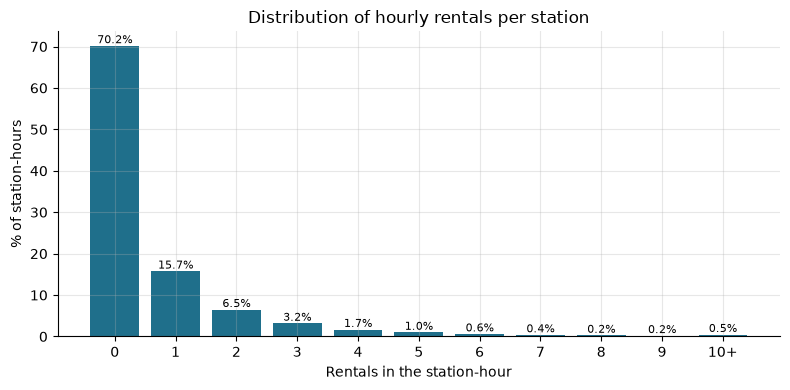

In [4]:
distribution = y.clip(upper = 10).value_counts(normalize = True).reindex(range(11), fill_value = 0) * 100

fig, ax = plt.subplots(figsize = (8, 4))
ax.bar(distribution.index, distribution.values, color = MAIN_COLOUR)
for x, value in distribution.items():
    ax.text(x, value, f'{value:.1f}%', ha = 'center', va = 'bottom', fontsize = 8)
ax.set_xticks(range(11), [str(i) for i in range(10)] + ['10+'])
ax.set(xlabel = 'Rentals in the station-hour', ylabel = '% of station-hours',
       title = 'Distribution of hourly rentals per station')
plt.tight_layout()
plt.show()

## 2. Temporal patterns

Mean rentals per station-hour by hour of day, for weekdays and weekends separately, with a summary of each
day type's peak hours.

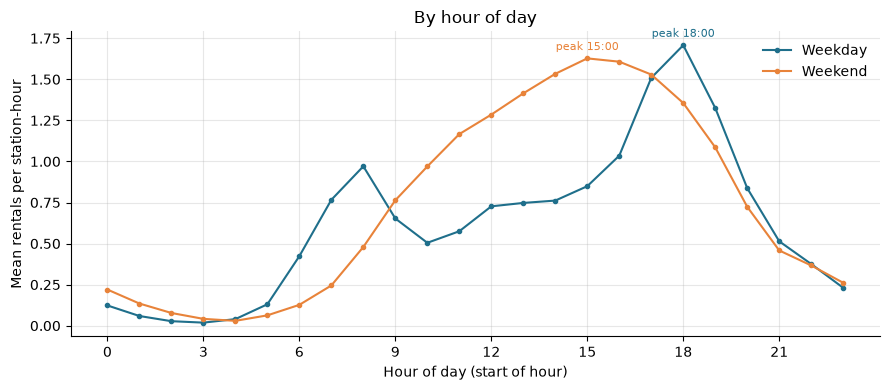

,Weekday,Weekend
overall peak,18:00 (1.71),15:00 (1.63)
morning peak,8:00 (0.97),11:00 (1.17)
afternoon/evening peak,18:00 (1.71),15:00 (1.63)
quietest hour,3:00 (0.019),4:00 (0.030)
top 3 hours,"18:00, 17:00, 19:00","15:00, 16:00, 14:00"


Weekday / weekend mean: {'Weekday': 0.621, 'Weekend': 0.732}


In [5]:
hourly = df.pivot_table(index = HOUR_OF_DAY, columns = DAY_TYPE, values = NUM_RENTALS, aggfunc = 'mean')


def plot_hourly(ax):
    ax.plot(hourly.index, hourly['Weekday'], marker = 'o', markersize = 3, color = MAIN_COLOUR, label = 'Weekday')
    ax.plot(hourly.index, hourly['Weekend'], marker = 'o', markersize = 3, color = SECOND_COLOUR, label = 'Weekend')
    for day_type, colour in [('Weekday', MAIN_COLOUR), ('Weekend', SECOND_COLOUR)]:
        peak_hour = hourly[day_type].idxmax()
        ax.annotate(f'peak {peak_hour}:00', (peak_hour, hourly.loc[peak_hour, day_type]),
                    textcoords = 'offset points', xytext = (0, 6), ha = 'center', fontsize = 8, color = colour)
    ax.set_xticks(range(0, 24, 3))
    ax.set(xlabel = 'Hour of day (start of hour)', ylabel = 'Mean rentals per station-hour', title = 'By hour of day')
    ax.legend(frameon = False)


fig, ax = plt.subplots(figsize = (9, 4))
plot_hourly(ax)
plt.tight_layout()
plt.show()

# peak summary per day type: overall peak, morning peak (hours 0-11), afternoon/evening peak (hours 12-23),
# quietest hour and the 3 busiest hours; values in brackets are mean rentals per station-hour
peak_hours = pd.DataFrame({
    day_type: {
        'overall peak': f'{hourly[day_type].idxmax()}:00 ({hourly[day_type].max():.2f})',
        'morning peak': f'{hourly[day_type].loc[:11].idxmax()}:00 ({hourly[day_type].loc[:11].max():.2f})',
        'afternoon/evening peak': f'{hourly[day_type].loc[12:].idxmax()}:00 ({hourly[day_type].loc[12:].max():.2f})',
        'quietest hour': f'{hourly[day_type].idxmin()}:00 ({hourly[day_type].min():.3f})',
        'top 3 hours': ', '.join(f'{hour}:00' for hour in hourly[day_type].nlargest(3).index),
    }
    for day_type in ['Weekday', 'Weekend']
})
display(peak_hours)
print('Weekday / weekend mean:', df.groupby(DAY_TYPE)[NUM_RENTALS].mean().round(3).to_dict())

### Peak hours

Weekdays show two commute peaks; weekends one broad afternoon high. The table gives each peak period's share of
station-hours and of rentals. The same definitions are used as evaluation subsets in `evaluate_subsets.ipynb`
(hour 7 = 07:00–07:59).

In [6]:
WEEKDAY_PEAK_HOURS = [7, 8, 16, 17, 18, 19]   # 07:00-09:00 and 16:00-20:00
WEEKEND_PEAK_HOURS = list(range(12, 18))      # 12:00-18:00

peak_subsets = {
    'Weekday peak (07-09, 16-20)': (df[DAY_TYPE] == 'Weekday') & df[HOUR_OF_DAY].isin(WEEKDAY_PEAK_HOURS),
    'Weekend peak (12-18)': (df[DAY_TYPE] == 'Weekend') & df[HOUR_OF_DAY].isin(WEEKEND_PEAK_HOURS),
}
peak_subsets['Either peak'] = peak_subsets['Weekday peak (07-09, 16-20)'] | peak_subsets['Weekend peak (12-18)']

display(pd.DataFrame({
    name: {
        '% of station-hours': mask.mean() * 100,
        '% of rentals': df.loc[mask, NUM_RENTALS].sum() / df[NUM_RENTALS].sum() * 100,
        'mean rentals per station-hour': df.loc[mask, NUM_RENTALS].mean(),
    }
    for name, mask in peak_subsets.items()
}).T.round(2))

,% of station-hours,% of rentals,mean rentals per station-hour
"Weekday peak (07-09, 16-20)",17.83,33.27,1.22
Weekend peak (12-18),7.18,16.48,1.50
Either peak,25.00,49.75,1.30


In [7]:
# mean rentals per station-hour by day of week (0 = Monday)
by_weekday = df.groupby(DAY_OF_WEEK)[NUM_RENTALS].mean()
by_weekday.index = ['Mon', 'Tue', 'Wed', 'Thu', 'Fri', 'Sat', 'Sun']
display(by_weekday.round(3).to_frame('mean rentals per station-hour'))

,mean rentals per station-hour
Mon,0.592
Tue,0.638
Wed,0.638
Thu,0.616
Fri,0.622
Sat,0.766
Sun,0.698


## 3. Station patterns

Stations ranked by mean rentals per station-hour: a chart of the top 10, the top 10's share of all rentals,
and tables of the 10 busiest and 5 quietest stations.

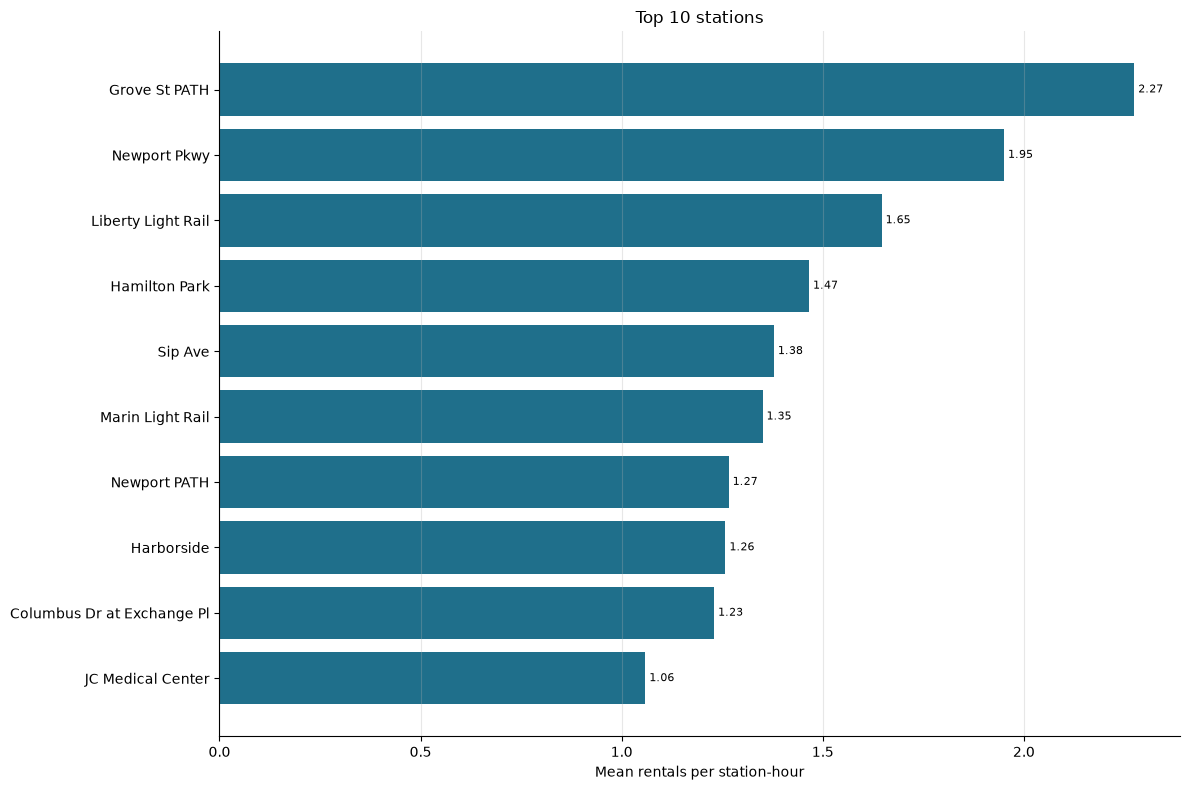

Top 10 stations: 44.7% of all rentals
Busiest / quietest station mean: 2.27 / 0.113

Largest stations:


,mean_rentals,total_rentals,share_with_rental,share_of_all_rentals_%
start station name,,,,
Grove St PATH,2.274,23197,0.589,6.828
Newport Pkwy,1.951,19895,0.544,5.856
Liberty Light Rail,1.646,16791,0.393,4.943
Hamilton Park,1.466,14950,0.514,4.401
Sip Ave,1.379,14060,0.550,4.139
Marin Light Rail,1.350,13772,0.488,4.054
Newport PATH,1.266,12913,0.446,3.801
Harborside,1.258,12831,0.455,3.777
Columbus Dr at Exchange Pl,1.230,12543,0.421,3.692


Smallest stations:


,mean_rentals,total_rentals,share_with_rental,share_of_all_rentals_%
start station name,,,,
Christ Hospital,0.166,1698,0.131,0.500
Dey St,0.162,1648,0.126,0.485
Union St,0.156,1593,0.122,0.469
Jackson Square,0.147,1502,0.118,0.442
Leonard Gordon Park,0.113,1152,0.091,0.339


In [8]:
stations = (
    df.groupby(STATION)
    .agg(mean_rentals = (NUM_RENTALS, 'mean'), total_rentals = (NUM_RENTALS, 'sum'), share_with_rental = ('has_rental', 'mean'))
    .sort_values('mean_rentals', ascending = False)
)
stations['share_of_all_rentals_%'] = stations['total_rentals'] / stations['total_rentals'].sum() * 100


def plot_stations(ax, top_n = 10):
    top = stations.head(top_n).iloc[::-1]   # busiest at the top
    ax.barh(top.index, top['mean_rentals'], color = MAIN_COLOUR)
    for y_position, value in enumerate(top['mean_rentals']):
        ax.text(value, y_position, f' {value:.2f}', va = 'center', fontsize = 8)
    ax.set(xlabel = 'Mean rentals per station-hour', title = f'Top {top_n} stations')
    ax.grid(axis = 'y', visible = False)


fig, ax = plt.subplots(figsize = (12, 8))
plot_stations(ax, top_n = 10)
plt.tight_layout()
plt.show()

print(f"Top 10 stations: {stations['share_of_all_rentals_%'].head(10).sum():.1f}% of all rentals")
print(f"Busiest / quietest station mean: {stations['mean_rentals'].iloc[0]:.2f} / {stations['mean_rentals'].iloc[-1]:.3f}")
print('\nLargest stations:')
display(stations.head(10).round(3))
print('Smallest stations:')
display(stations.tail(5).round(3))

## 4. Test set check (Mar–Apr 2021)

The analyses from sections 1–3 repeated on the test period and compared with train + validation, to check that
the patterns still hold. Descriptive only: nothing here was used for any modelling decision. The peak-hour
definitions and the train + validation results are reused from the sections above.

In [9]:
test_df = pd.read_csv(data_dir + 'intermediate_processing/full_features.csv', parse_dates = [DATE])
test_df = test_df[test_df[DATE] >= TEST_START].copy()   # test period only

test_df[DAY_TYPE] = np.where(test_df[DAY_OF_WEEK] >= 5, 'Weekend', 'Weekday')
test_df['has_rental'] = test_df[NUM_RENTALS] > 0

print(f'{len(test_df):,} station-hours, {test_df[STATION].nunique()} stations, '
      f'{test_df[DATE].min().date()} to {test_df[DATE].max().date()}')

74,409 station-hours, 51 stations, 2021-03-01 to 2021-04-30


### Target overview

Summary statistics and count distribution, train + validation vs test.

In [10]:
def target_overview(frame):
    values = frame[NUM_RENTALS]
    return pd.Series({
        'station-hours': len(values),
        'total rentals': values.sum(),
        'zero station-hours (%)': (values == 0).mean() * 100,
        'mean rentals per station-hour': values.mean(),
        'variance': values.var(),
        'variance / mean': values.var() / values.mean(),
        'mean rentals when > 0': values[values > 0].mean(),
        '99th percentile': values.quantile(0.99),
        'max': values.max(),
    })


display(pd.DataFrame({'Train + validation': target_overview(df), 'Test': target_overview(test_df)}).round(3))

,Train + validation,Test
station-hours,520149.000,74409.000
total rentals,339711.000,40136.000
zero station-hours (%),70.163,71.579
mean rentals per station-hour,0.653,0.539
variance,2.360,1.473
variance / mean,3.613,2.730
mean rentals when > 0,2.189,1.898
99th percentile,7.000,6.000
max,46.000,33.000


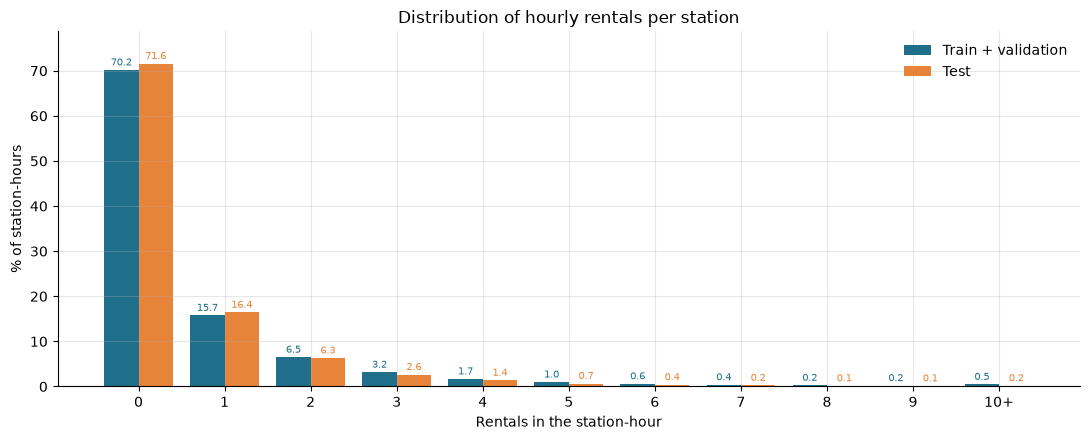

In [11]:
test_distribution = test_df[NUM_RENTALS].clip(upper = 10).value_counts(normalize = True).reindex(range(11), fill_value = 0) * 100

fig, ax = plt.subplots(figsize = (11, 4.5))
width = 0.4
for offset, values, colour, label in [
    (-width / 2, distribution, MAIN_COLOUR, 'Train + validation'),
    (width / 2, test_distribution, SECOND_COLOUR, 'Test'),
]:
    ax.bar(values.index + offset, values.values, width, color = colour, label = label)
    # % of station-hours above each bar
    for x, value in values.items():
        ax.text(x + offset, value + 0.5, f'{value:.1f}', ha = 'center', va = 'bottom', fontsize = 7, color = colour)
ax.set_xticks(range(11), [str(i) for i in range(10)] + ['10+'])
ax.set_ylim(0, max(distribution.max(), test_distribution.max()) * 1.1)
ax.set(xlabel = 'Rentals in the station-hour', ylabel = '% of station-hours',
       title = 'Distribution of hourly rentals per station')
ax.legend(frameon = False)
plt.tight_layout()
plt.show()

### Temporal patterns

Hourly profile for weekdays (left) and weekends (right), train + validation vs test (report figure), followed by the
test period's peak summary, peak-period shares (with a train + validation vs test comparison of the share
of rentals) and mean rentals by day of week.

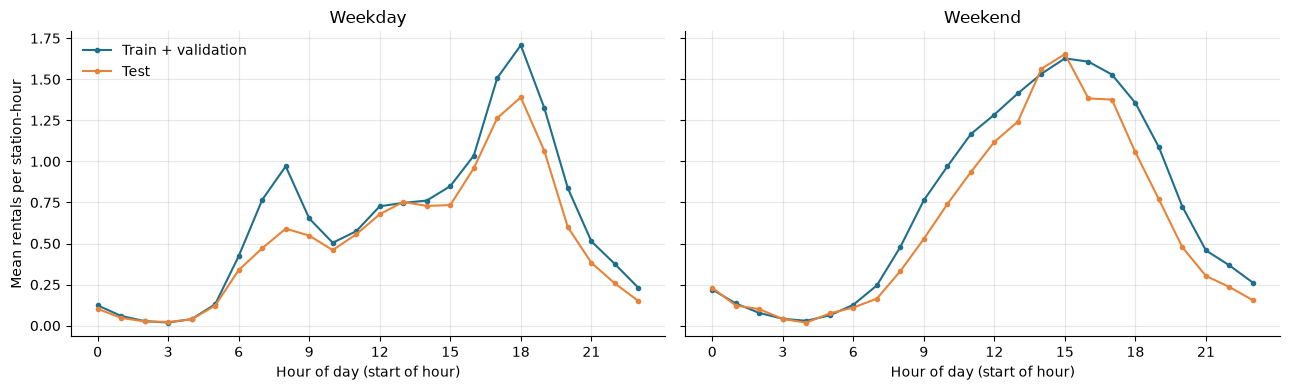

,Weekday,Weekend
overall peak,18:00 (1.39),15:00 (1.65)
morning peak,8:00 (0.59),11:00 (0.94)
afternoon/evening peak,18:00 (1.39),15:00 (1.65)
quietest hour,3:00 (0.022),4:00 (0.018)
top 3 hours,"18:00, 17:00, 19:00","15:00, 14:00, 16:00"


Weekday / weekend mean: {'Weekday': 0.512, 'Weekend': 0.615}


In [12]:
test_hourly = test_df.pivot_table(index = HOUR_OF_DAY, columns = DAY_TYPE, values = NUM_RENTALS, aggfunc = 'mean')

fig, axes = plt.subplots(1, 2, figsize = (13, 4), sharey = True)
for ax, day_type in zip(axes, ['Weekday', 'Weekend']):
    ax.plot(hourly.index, hourly[day_type], marker = 'o', markersize = 3, color = MAIN_COLOUR, label = 'Train + validation')
    ax.plot(test_hourly.index, test_hourly[day_type], marker = 'o', markersize = 3, color = SECOND_COLOUR, label = 'Test')
    ax.set_xticks(range(0, 24, 3))
    ax.set(xlabel = 'Hour of day (start of hour)', title = day_type)
axes[0].set_ylabel('Mean rentals per station-hour')
axes[0].legend(frameon = False)
plt.tight_layout()
plt.show()

test_peak_hours = pd.DataFrame({
    day_type: {
        'overall peak': f'{test_hourly[day_type].idxmax()}:00 ({test_hourly[day_type].max():.2f})',
        'morning peak': f'{test_hourly[day_type].loc[:11].idxmax()}:00 ({test_hourly[day_type].loc[:11].max():.2f})',
        'afternoon/evening peak': f'{test_hourly[day_type].loc[12:].idxmax()}:00 ({test_hourly[day_type].loc[12:].max():.2f})',
        'quietest hour': f'{test_hourly[day_type].idxmin()}:00 ({test_hourly[day_type].min():.3f})',
        'top 3 hours': ', '.join(f'{hour}:00' for hour in test_hourly[day_type].nlargest(3).index),
    }
    for day_type in ['Weekday', 'Weekend']
})
display(test_peak_hours)
print('Weekday / weekend mean:', test_df.groupby(DAY_TYPE)[NUM_RENTALS].mean().round(3).to_dict())

In [13]:
test_peak_subsets = {
    'Weekday peak (07-09, 16-20)': (test_df[DAY_TYPE] == 'Weekday') & test_df[HOUR_OF_DAY].isin(WEEKDAY_PEAK_HOURS),
    'Weekend peak (12-18)': (test_df[DAY_TYPE] == 'Weekend') & test_df[HOUR_OF_DAY].isin(WEEKEND_PEAK_HOURS),
}
test_peak_subsets['Either peak'] = test_peak_subsets['Weekday peak (07-09, 16-20)'] | test_peak_subsets['Weekend peak (12-18)']

display(pd.DataFrame({
    name: {
        '% of station-hours': mask.mean() * 100,
        '% of rentals': test_df.loc[mask, NUM_RENTALS].sum() / test_df[NUM_RENTALS].sum() * 100,
        'mean rentals per station-hour': test_df.loc[mask, NUM_RENTALS].mean(),
    }
    for name, mask in test_peak_subsets.items()
}).T.round(2))

# share of all rentals in each peak period, train + validation vs test (the figures quoted in the report)
display(pd.DataFrame({
    'Train + validation': {name: df.loc[mask, NUM_RENTALS].sum() / df[NUM_RENTALS].sum() * 100 for name, mask in peak_subsets.items()},
    'Test': {name: test_df.loc[mask, NUM_RENTALS].sum() / test_df[NUM_RENTALS].sum() * 100 for name, mask in test_peak_subsets.items()},
}).round(1).rename_axis('% of rentals'))

,% of station-hours,% of rentals,mean rentals per station-hour
"Weekday peak (07-09, 16-20)",18.51,32.81,0.96
Weekend peak (12-18),6.58,16.95,1.39
Either peak,25.09,49.77,1.07


,Train + validation,Test
% of rentals,,
"Weekday peak (07-09, 16-20)",33.3,32.8
Weekend peak (12-18),16.5,17.0
Either peak,49.7,49.8


In [14]:
# mean rentals per station-hour by day of week, train + validation vs test
test_by_weekday = test_df.groupby(DAY_OF_WEEK)[NUM_RENTALS].mean()
test_by_weekday.index = ['Mon', 'Tue', 'Wed', 'Thu', 'Fri', 'Sat', 'Sun']
display(pd.DataFrame({'Train + validation': by_weekday, 'Test': test_by_weekday}).round(3))

,Train + validation,Test
Mon,0.592,0.448
Tue,0.638,0.600
Wed,0.638,0.540
Thu,0.616,0.444
Fri,0.622,0.532
Sat,0.766,0.719
Sun,0.698,0.510


### Station patterns

Test-period station ranking (with each station's train + validation rank for comparison), followed by the top 10
stations of each period side by side (report figure).

In [15]:
test_stations = (
    test_df.groupby(STATION)
    .agg(mean_rentals = (NUM_RENTALS, 'mean'), total_rentals = (NUM_RENTALS, 'sum'), share_with_rental = ('has_rental', 'mean'))
    .sort_values('mean_rentals', ascending = False)
)
test_stations['share_of_all_rentals_%'] = test_stations['total_rentals'] / test_stations['total_rentals'].sum() * 100
# rank of each station in train + validation (1 = busiest)
test_stations['train_validation_rank'] = stations.index.get_indexer(test_stations.index) + 1

print(f"Top 10 stations: {test_stations['share_of_all_rentals_%'].head(10).sum():.1f}% of all rentals")
print(f"Busiest / quietest station mean: {test_stations['mean_rentals'].iloc[0]:.2f} / {test_stations['mean_rentals'].iloc[-1]:.3f}")
print(f"Train + validation top 10 also in the test top 10: {len(set(stations.index[:10]) & set(test_stations.index[:10]))} of 10")
print('\nLargest stations:')
display(test_stations.head(10).round(3))
print('Smallest stations:')
display(test_stations.tail(5).round(3))

Top 10 stations: 44.8% of all rentals
Busiest / quietest station mean: 1.67 / 0.075
Train + validation top 10 also in the test top 10: 10 of 10

Largest stations:


,mean_rentals,total_rentals,share_with_rental,share_of_all_rentals_%,train_validation_rank
start station name,,,,,
Grove St PATH,1.666,2431,0.561,6.057,1
Newport Pkwy,1.594,2325,0.546,5.793,2
Liberty Light Rail,1.468,2142,0.426,5.337,3
Hamilton Park,1.216,1774,0.526,4.420,4
Marin Light Rail,1.184,1728,0.498,4.305,6
Sip Ave,1.170,1707,0.546,4.253,5
Newport PATH,1.144,1669,0.470,4.158,7
Columbus Dr at Exchange Pl,1.001,1461,0.395,3.640,9
Harborside,0.973,1420,0.463,3.538,8


Smallest stations:


,mean_rentals,total_rentals,share_with_rental,share_of_all_rentals_%,train_validation_rank
start station name,,,,,
Dey St,0.119,173,0.101,0.431,48
5 Corners Library,0.097,142,0.078,0.354,46
Leonard Gordon Park,0.092,134,0.071,0.334,51
York St,0.079,115,0.062,0.287,39
Union St,0.075,109,0.062,0.272,49


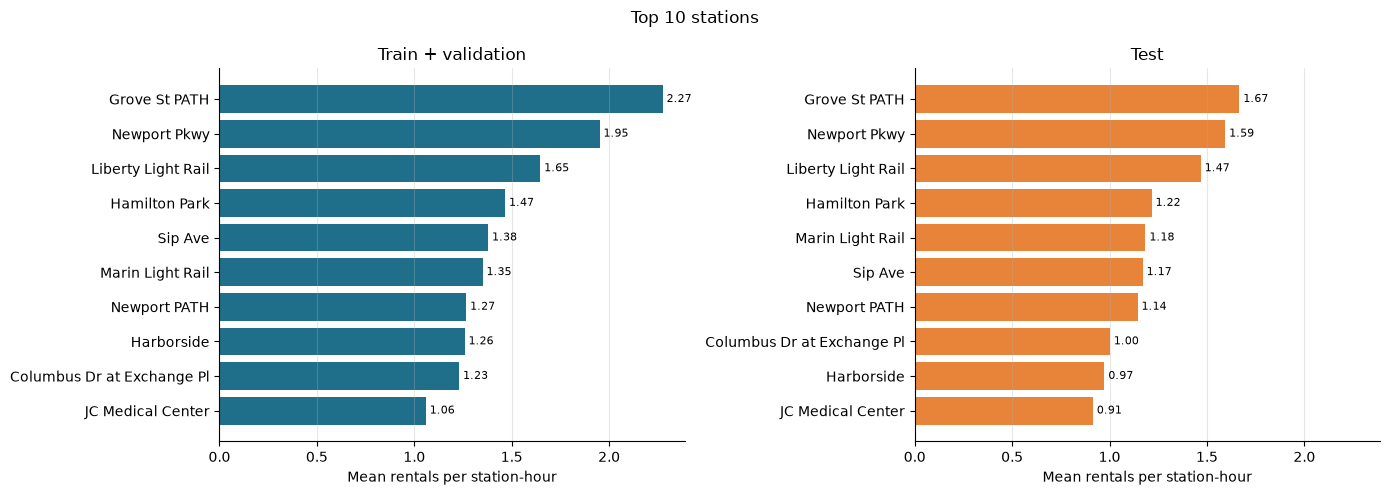

In [16]:
# top 10 stations in each period, each ranked by its own period's mean rentals
fig, axes = plt.subplots(1, 2, figsize = (14, 5), sharex = True)
for ax, (period, station_table, colour) in zip(axes, [
    ('Train + validation', stations, MAIN_COLOUR),
    ('Test', test_stations, SECOND_COLOUR),
]):
    top = station_table.head(10).iloc[::-1]   # busiest at the top
    ax.barh(top.index, top['mean_rentals'], color = colour)
    for y_position, value in enumerate(top['mean_rentals']):
        ax.text(value, y_position, f' {value:.2f}', va = 'center', fontsize = 8)
    ax.set(xlabel = 'Mean rentals per station-hour', title = period)
    ax.grid(axis = 'y', visible = False)
fig.suptitle('Top 10 stations')
plt.tight_layout()
plt.show()